# This document Combines and compared Controller and Robot Classes 

**Merged (2026-11-14), what applies to every controller below:**

* **Frames:** every model's velocity state is global (Henry's convention): Newton's law holds as it is, with no rotational term. The velocity along the robot's axes is worked out only where a wheel needs it.
* **Current:** every MPC keeps |i1| + |i2| + |i3| + |i4| <= 7.4 A at every predicted step (`total_current_limit`); the LQR and the PID clip at it. 7.4 A is the Pololu total at which the robot's BLDCs, doing the same motion, would draw their 15 A from the battery (notes/2026-11-13/1400_2PM/CURRENT_LIMIT_DERIVATION.md). The plant itself limits at 15 A (`I_total_max`).
* **Cost weights:** one set for every controller with a cost (the MPCs and the LQR): `COST_WEIGHTS` in the controller settings, Henry's Bryson rule or Dana's set. The LQR has the same voltage-change cost as the MPCs. Every MPC's terminal cost is the Riccati one by default (`terminal_cost`: 'riccati' or 'fixed').
* **Waypoints:** a waypoint is settled when the robot is within `ARRIVE_THRESHOLD_POS` (3 cm) and below `ARRIVE_THRESHOLD_VEL` (1 cm/s); an X on the trajectory plot marks a waypoint not attained, where the robot was when the path moved on.





In [85]:
import time

class CodeTimer:
    """
    A versatile timer class for measuring elapsed execution time with 
    support for starting, pausing, resuming, and resetting.
    """
    def __init__(self):
        self.reset()

    def start(self):
        """Starts the timer from a fresh state or restarts it."""
        self._start_time = time.perf_counter()
        self._elapsed_time = 0.0
        self._is_running = True

    def pause(self):
        """Pauses the timer if it is currently running."""
        if self._is_running:
            self._elapsed_time += time.perf_counter() - self._start_time
            self._is_running = False

    def resume(self):
        """Resumes the timer if it was paused."""
        if not self._is_running:
            self._start_time = time.perf_counter()
            self._is_running = True

    def reset(self):
        """Resets all timer counters and stops the timer."""
        self._start_time = 0.0
        self._elapsed_time = 0.0
        self._is_running = False

    @property
    def elapsed(self) -> float:
        """Returns the total elapsed time in seconds, updating live if running."""
        if self._is_running:
            return self._elapsed_time + (time.perf_counter() - self._start_time)
        return self._elapsed_time


In [86]:
import numpy as np
import matplotlib.pyplot as plt
import time

# =======================================================================
# 0. BRING IN FUNCTIONS FROM OTHER NOTEBOOKS
# =======================================================================

from IPython.utils.capture import capture_output
global SIMULATION_PARAMATERS, PathGenerator, OmniRobotSimulationExplicit
# This forces the native Jupyter runner to execute the notebook silently
with capture_output():
    %run "PlantModels.ipynb"
    %run "ControllerModels.ipynb"
    %run "PathGeneration.ipynb"


## MULTI POINT PATH TRACKING SIMULATION WITH CONTROLLER COMPARISON

In [87]:
# paramaters and classed are defined in xxxx.ipynb and imported above, so we need to declare them as global to avoid "undefined variable" errors
global model_choice, SIMULATION_PARAMATERS, PathGenerator, PathGeneratorWithHold
global OmniRobotSimulationExplicit, OmniRobotStateExplicit, OmniRobotSimulationODESolve, OmniRobotStateODESolve
global CascadedPIDController, MPCControllerSimple


In [88]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Circle
import time

# =======================================================================
# SETUP MULTI-WAYPOINT TRAJECTORY WITH HOLDS
# =======================================================================
DT_CTRL = 0.02
DT_PLANT = SIMULATION_PARAMATERS['dt']
SUBSTEPS = DT_CTRL/DT_PLANT
PathGenerator_Multi = PathGeneratorWithHold(dt=DT_CTRL)

ARRIVE_THRESHOLD_POS = 0.03 # 3.0 cm
ARRIVE_THRESHOLD_VEL = 0.01    # 1.0 cm/s
ARRIVE_THRESHOLD_THETA = 10


WAYPOINTS = [
    np.array([0.0, 0.0, 0.0]),
    np.array([2.2, 1.2, 0.50]),
    np.array([1.0, 3.5, -0.60]),
    np.array([3.2, 2.8, 0.785])
]
x_wp = 0.5*np.cos(np.radians(-90))
y_wp = 0.5*np.sin(np.radians(-90))
t_wp=np.radians(-180)
#WAYPOINTS = [    np.array([0.0, 0.0, 0.0]),    np.array([x_wp, y_wp, t_wp])]

SEGMENT_DURATION = 5.0
HOLD_DURATION = 0.5

path_data=PathGenerator_Multi.generate_waypoints_sequence(waypoints=WAYPOINTS,segment_duration=SEGMENT_DURATION,segment_hold=HOLD_DURATION)

WP_TIMESTAMPS = path_data['segment_boundaries']
POS_REF = path_data['pos']
VEL_REF = path_data['vel']
N_STEPS = len(path_data['pos'])
T_REF = path_data['t']
V_LOCAL_REF = path_data['pos_local']


print(f"=======================================================================")
print(f"   MULTI-WAYPOINT TRAJECTORY GENERATED ({N_STEPS} steps | {T_REF[-1]:.2f} s)")
print(f"=======================================================================")
for idx, wp in enumerate(WAYPOINTS):
    print(f" • Waypoint {idx}: [{wp[0]:.2f}m, {wp[1]:.2f}m, {np.degrees(wp[2]):.1f}°] | Scheduled Arrival: {WP_TIMESTAMPS[idx]:.1f} s")
print(f"=======================================================================")


   MULTI-WAYPOINT TRAJECTORY GENERATED (823 steps | 16.44 s)
 • Waypoint 0: [0.00m, 0.00m, 0.0°] | Scheduled Arrival: 0.0 s
 • Waypoint 1: [2.20m, 1.20m, 28.6°] | Scheduled Arrival: 5.5 s
 • Waypoint 2: [1.00m, 3.50m, -34.4°] | Scheduled Arrival: 11.0 s
 • Waypoint 3: [3.20m, 2.80m, 45.0°] | Scheduled Arrival: 16.4 s


In [89]:

# =======================================================================
# SETUP CONTROLLER SETTINGS
# =======================================================================


ctrl_PID = CascadedPIDController(
            SIMULATION_PARAMATERS,
            pos_pid_gains={'kp': 3.0, 'ki': 0.2, 'kd': 0.05},
            wheel_pid_gains={'kp': 0.15, 'ki': 0.8, 'kd': 0.0},
            dt=DT_CTRL, a_max=15, alpha_max=10.0, 
            k_theta=3.0, voltage_limit=SIMULATION_PARAMATERS['V_max']
        )

# One set of cost weights for every controller with a cost (the MPCs and the LQR)
COST_WEIGHTS = 'bryson'         # 'bryson' (Henry) or 'dana'
if COST_WEIGHTS == 'bryson':
    # Bryson's rule: weight = 1 / (largest acceptable value)^2
    max_pos_err = 0.05                      # m
    max_heading_err = np.radians(5.0)       # rad
    max_vel_err = 0.10                      # m/s
    max_dV = 0.5                            # V per 20 ms step: the main voltage cost
    # The light cost on the voltage itself: the voltage that holds the top wheel speed and pushes at the grip limit
    w_top = 40.0                            # rad/s
    i_grip = SIMULATION_PARAMATERS['mu_s'] * SIMULATION_PARAMATERS['Mr'] * SIMULATION_PARAMATERS['g'] / 4 * SIMULATION_PARAMATERS['r'] / SIMULATION_PARAMATERS['Kt']
    max_V = SIMULATION_PARAMATERS['Kb'] * w_top + SIMULATION_PARAMATERS['R'] * i_grip
    HORIZON = 8
    Q_POSITION = (1 / max_pos_err**2, 1 / max_pos_err**2, 1 / max_heading_err**2)
    Q_VELOCITY = (1 / max_vel_err**2, 1 / max_vel_err**2, 1 / (max_vel_err / SIMULATION_PARAMATERS['Rb'])**2)
    R_VOLTAGE = 1 / max_V**2
    R_SLEW = 1 / max_dV**2
    DELTA_V_LIMIT = 5.0
    P_POSITION = None                       # terminal weights: P_MULTIPLY x the stage weights
    P_VELOCITY = None
else:
    # Dana's set
    HORIZON=5
    Q_POSITION = (101.0, 101.0, 60.0)
    Q_VELOCITY = (1.0, 1.0, 1.0)
    R_VOLTAGE=0.001
    DELTA_V_LIMIT=1
    P_POSITION = (1000.0, 1000.0, 1000.0)
    P_VELOCITY=None
    R_SLEW = 0.001
P_MULTIPLY=10

ctrl_MPC_simple = MPCControllerSimple(
            SIMULATION_PARAMATERS, horizon_K=HORIZON, dt=DT_CTRL,
            q_pose=Q_POSITION, q_vel=Q_VELOCITY,
            r_voltage=R_VOLTAGE, r_slew=R_SLEW, 
            voltage_limit=SIMULATION_PARAMATERS['V_max'], current_limit = SIMULATION_PARAMATERS['I_max'], 
            delta_v_max=DELTA_V_LIMIT,
            p_multiply=P_MULTIPLY,
            p_pose_fin=P_POSITION,  p_vel_fin=P_VELOCITY
            )
ctrl_lqr = LQRController( SIMULATION_PARAMATERS,
                 dt=DT_CTRL,
                 q_pose=Q_POSITION, q_vel=Q_VELOCITY,
                 r_voltage=R_VOLTAGE, r_slew=R_SLEW,     # r_slew, the MPCs' voltage-change cost
                 voltage_limit=SIMULATION_PARAMATERS['V_max'],
                 delta_v_max=DELTA_V_LIMIT,
                 )
ctrl_coulomb=SaturatedCoulombMPCController( 
                 SIMULATION_PARAMATERS, horizon_K=HORIZON, dt=DT_CTRL,
                 q_pose=Q_POSITION, q_vel=Q_VELOCITY,
                 r_voltage=R_VOLTAGE, r_slew=R_SLEW, 
                 voltage_limit=SIMULATION_PARAMATERS['V_max'], 
                 delta_v_max=DELTA_V_LIMIT,
                 p_pose=P_POSITION,  p_vel=P_VELOCITY)
ctrl_DOB = LumpedDOBMPCController(
                SIMULATION_PARAMATERS, horizon_K=HORIZON, dt=DT_CTRL,
                 q_pose=Q_POSITION, q_vel=Q_VELOCITY,
                 r_voltage=R_VOLTAGE, r_slew=R_SLEW, 
                 voltage_limit=SIMULATION_PARAMATERS['V_max'], 
                 delta_v_max=DELTA_V_LIMIT,
                 p_pose=P_POSITION,  p_vel=P_VELOCITY)
#TODO: CHECK IMPLEMINTATION TO SEE THE INPUTS SETUP
ctrl_lin_henry=MPCControllerLinearized( 
                 SIMULATION_PARAMATERS, horizon_K=HORIZON, dt=DT_CTRL,
                 q_pose=Q_POSITION, q_vel=Q_VELOCITY,
                 r_voltage=R_VOLTAGE, r_slew=R_SLEW, 
                 voltage_limit=SIMULATION_PARAMATERS['V_max'], current_limit = SIMULATION_PARAMATERS['I_max'], 
                 delta_v_max=DELTA_V_LIMIT,
                 p_multiply=P_MULTIPLY,
                 p_pose_fin=P_POSITION,  p_vel_fin=P_VELOCITY
                )

Controller_Dictionary = {
    'Cascaded PID': ('pid', ctrl_PID, 'tab:red'),
    'Simple MPC': ('simple_mpc', ctrl_MPC_simple, 'tab:blue'),
    'LQR Infinite': ('lqr',ctrl_lqr,'tab:green'),
    'DOB MPC': ('DOB_mpc', ctrl_DOB, 'tab:brown'),
    'Coulomb MPC': ('coulomb_mpc', ctrl_coulomb, 'tab:purple'),
    'lin henry MPC' :('lim_h',ctrl_lin_henry,'tab:pink'),
    #'Method 3 (LuGre MPC)': ('m3', ctrl_m3, 'tab:pink')
}





In [90]:
# =======================================================================
# CREATE SIMULATION RUNNER FUNCTION
# =======================================================================
ENABLE_DEADBAND=True

def run_multi_waypoint_benchmark(ctrl_tuple, 
                                 n_steps,waypoints,wp_timestamps,
                                 pos_ref,v_local_ref,enable_deadband: bool = True):
    ctrl_type, controller, _ = ctrl_tuple
    plant = OmniRobotSimulationODESolve(SIMULATION_PARAMATERS, random_seed=42)
    plant_state = OmniRobotStateODESolve()
    substeps=int(controller.dt/ plant.dt)

    t_ref=np.arange(len(np.vstack(pos_ref))) * controller.dt
    
    log_t, log_pos, log_v, log_V, log_slip, log_z, log_I = [], [], [], [], [], [], []
    arrivals = [None] * len(waypoints)
    arrivals[0] = 0.0
    
    if hasattr(controller, 'reset'):
        controller.reset()

    timer=CodeTimer()
    timer.start()
    if ctrl_type == 'pid':
        horizon = 1
    elif ctrl_type == 'lqr':
        horizon =1
    else:
        horizon=controller.K
    
    for k in range(n_steps):
        obs = plant.get_observable_state(plant_state)

        if k + horizon + 1 <= n_steps:
            pos_h = pos_ref[k : k + horizon + 1].copy()
            vel_h = v_local_ref[k : k + horizon + 1].copy()
        else:
            pad_len = (k + horizon + 1) - n_steps
            pos_h = np.vstack([pos_ref[k:], np.tile(pos_ref[-1], (pad_len, 1))]).copy()
            vel_h = np.vstack([v_local_ref[k:], np.zeros((pad_len, 3))]).copy()
            
        curr_t = t_ref[k]
        active_wp_idx = 1
        for idx in range(1, len(wp_timestamps)):
            if curr_t >= wp_timestamps[idx-1] - 0.5:
                active_wp_idx = idx
        active_wp = waypoints[min(active_wp_idx, len(waypoints)-1)]
        
        dist_to_wp = np.hypot(active_wp[0] - plant_state.pos_global[0], active_wp[1] - plant_state.pos_global[1])
        speed = np.hypot(plant_state.v_local[0], plant_state.v_local[1])
        
        if arrivals[active_wp_idx] is None and dist_to_wp <= ARRIVE_THRESHOLD_POS and speed <= ARRIVE_THRESHOLD_VEL:
            arrivals[active_wp_idx] = curr_t
            
        is_arrived_hold = (dist_to_wp <= ARRIVE_THRESHOLD_POS) and (speed <= ARRIVE_THRESHOLD_VEL) and (np.linalg.norm(v_local_ref[k]) < 1e-3)
        
        if enable_deadband and is_arrived_hold:
            u0 = np.zeros(4)
        else:
            if ctrl_type == 'pid':
                u0 = controller.compute(pos_ref[k], obs)
            else:
                u0 = controller.compute_optimal_u0(obs, pos_h, vel_h)

        timer.pause()        
        for q in range(int(substeps)):
            plant_state = plant.step(plant_state, u0)
            # A controller with a 1 ms observer (the linearized MPC's 'observer') gets every plant step's readings,
            # and the camera's pose at the last one (every 20 ms)
            if hasattr(controller, 'estimator_update'):
                controller.estimator_update(plant.get_observable_state(plant_state), camera_frame=(q == int(substeps) - 1))
            
        v_contact = plant.H @ plant_state.v_local
        v_slip_k = v_contact - SIMULATION_PARAMATERS['r'] * plant_state.omega
        
        log_t.append(t_ref[k])
        log_pos.append(plant_state.pos_global.copy())
        log_v.append(plant_state.v_local.copy())
        log_V.append(u0.copy())
        log_I.append(plant_state.I.copy())
        log_slip.append(v_slip_k.copy())
        log_z.append(plant_state.z.copy())
        timer.resume()   
        
    log_pos = np.array(log_pos)
    pos_err = np.hypot(pos_ref[:, 0] - log_pos[:, 0], pos_ref[:, 1] - log_pos[:, 1])# Time-indexed position tracking error
    
    return {
        't': np.array(log_t),
        'pos': log_pos,
        'v_local': np.array(log_v),
        'V_cmd': np.array(log_V),
        'I': np.array(log_I),
        'v_slip': np.array(log_slip),
        'z': np.array(log_z),
        'pos_err': pos_err,
        'arrival_times': arrivals,
        
        'exec_time': timer.elapsed
    }



In [ ]:
# =======================================================================
# EXECUTE WAYPOINT SIMULATION RUNNER
# =======================================================================

print(f"\nExecuting Multi-Waypoint Benchmark Simulations .........")
results_multi_db = {}

for name, ctuple in Controller_Dictionary.items():
    print(f"Running {name} Simulation")
    results_multi_db[name] = run_multi_waypoint_benchmark(ctuple, N_STEPS,WAYPOINTS,WP_TIMESTAMPS,
                                     POS_REF,VEL_REF, enable_deadband=ENABLE_DEADBAND,)   # Global convention: the global reference velocity
print(f"\n Completed all simulations")  


Executing Multi-Waypoint Benchmark Simulations .........
Running Cascaded PID Simulation



              WAYPOINT PATH TRACKING SUMMARY
Controller        | RMS Time Err (cm) | Max Spatial Err (cm) | Max Slip (mm/s)   | Step Time (ms)    | Max Input (V)     | WP1 Arrival (s)   | WP2 Arrival (s)   | WP3 Arrival (s)   | 
--------------------------------------------------------------------------------------------------------------------------------------------------------------------
Cascaded PID      | 14.46             | 3.38              | 167.52            | 0.09              | 8.70              |4.78s             | No Arrival        | 16.18s            | 
Simple MPC        | 0.85              | 0.60              | 3.46              | 4.67              | 8.42              |4.88s             | 10.36s            | 15.84s            | 
LQR Infinite      | 1.07              | 0.24              | 3.51              | 1.19              | 8.43              |4.86s             | 10.34s            | 15.80s            | 
DOB MPC           | 0.86              | 0.59              | 3.48 

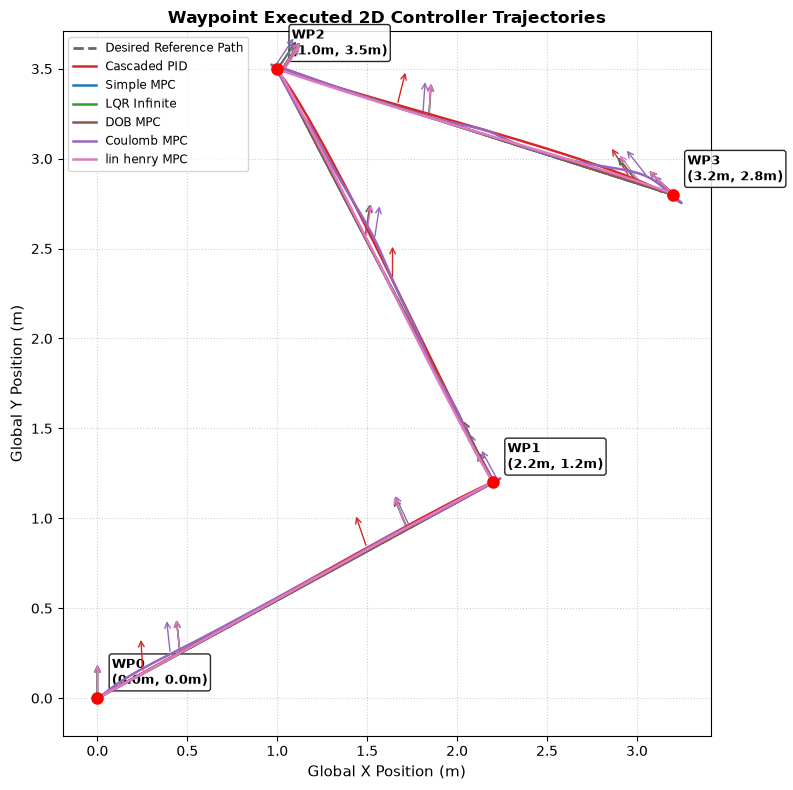

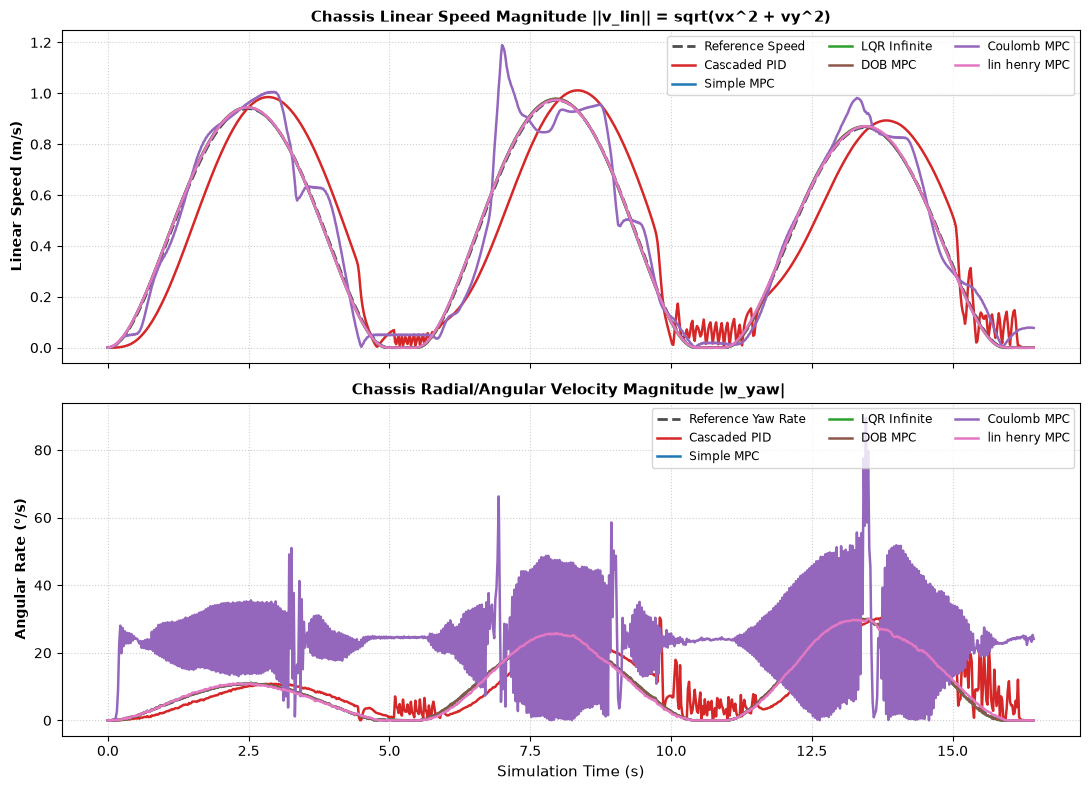

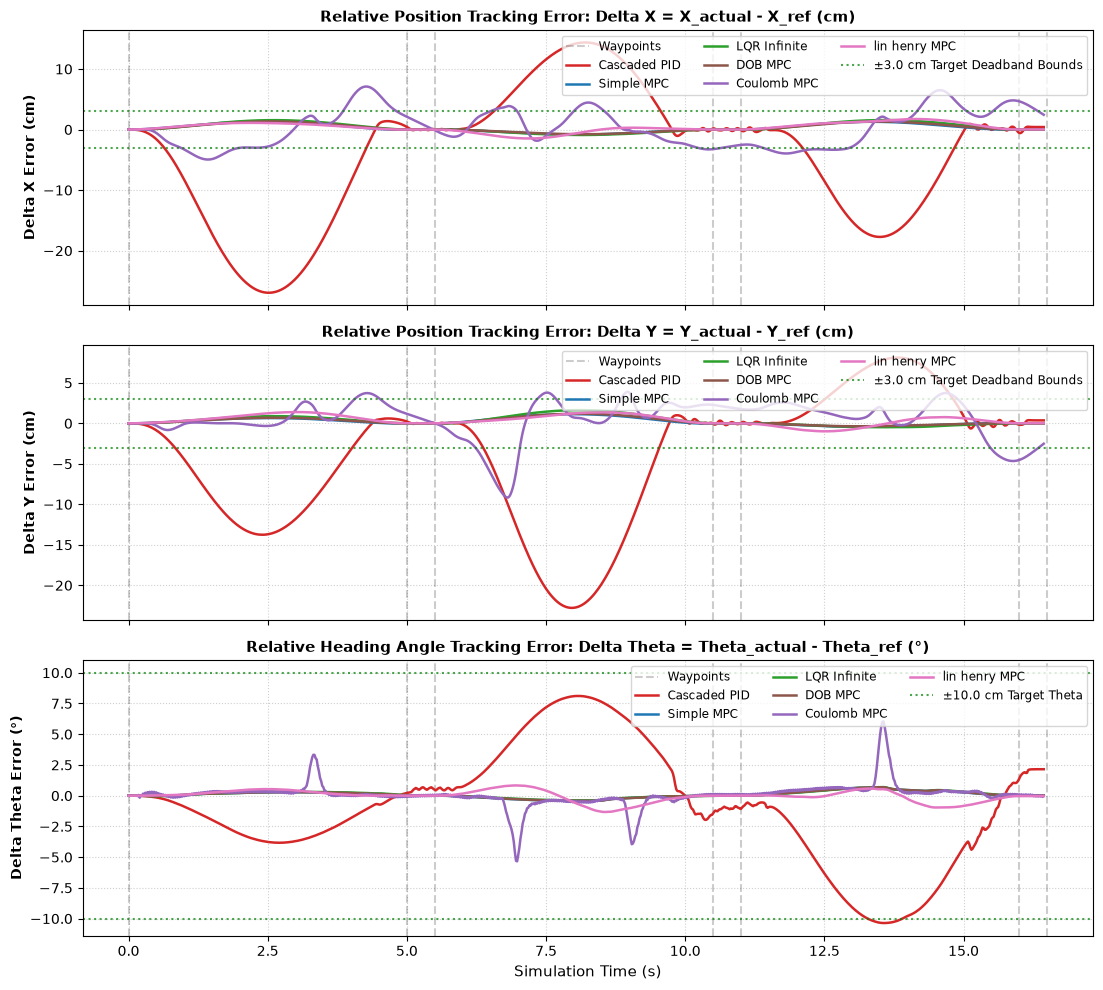

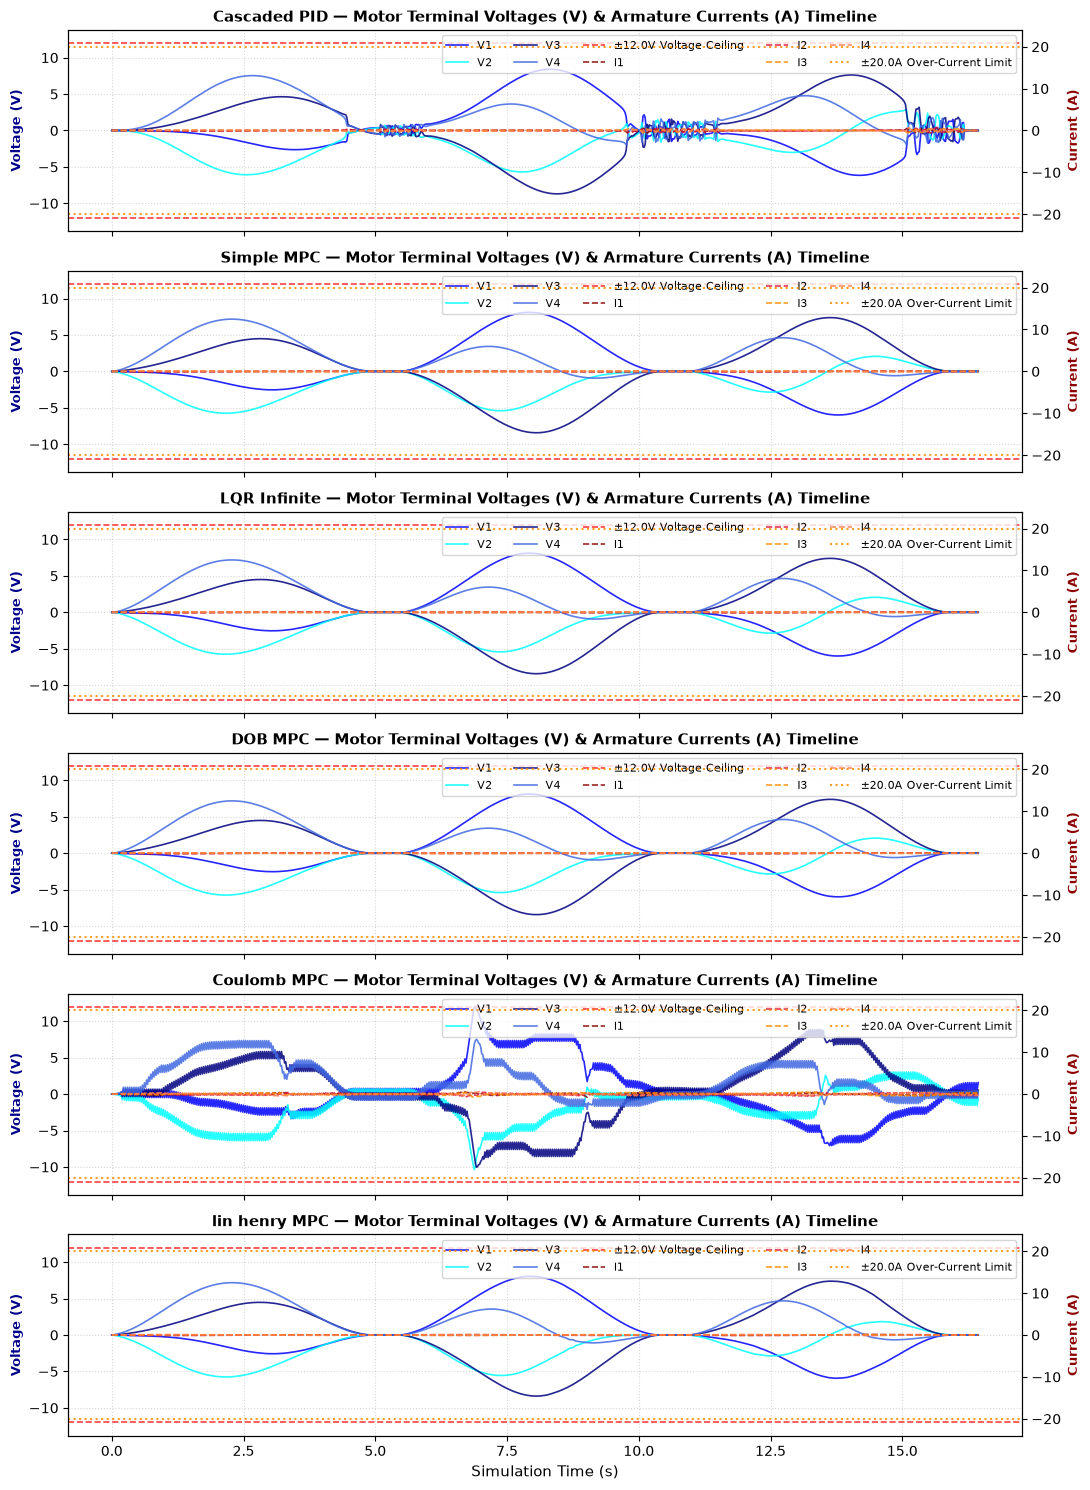

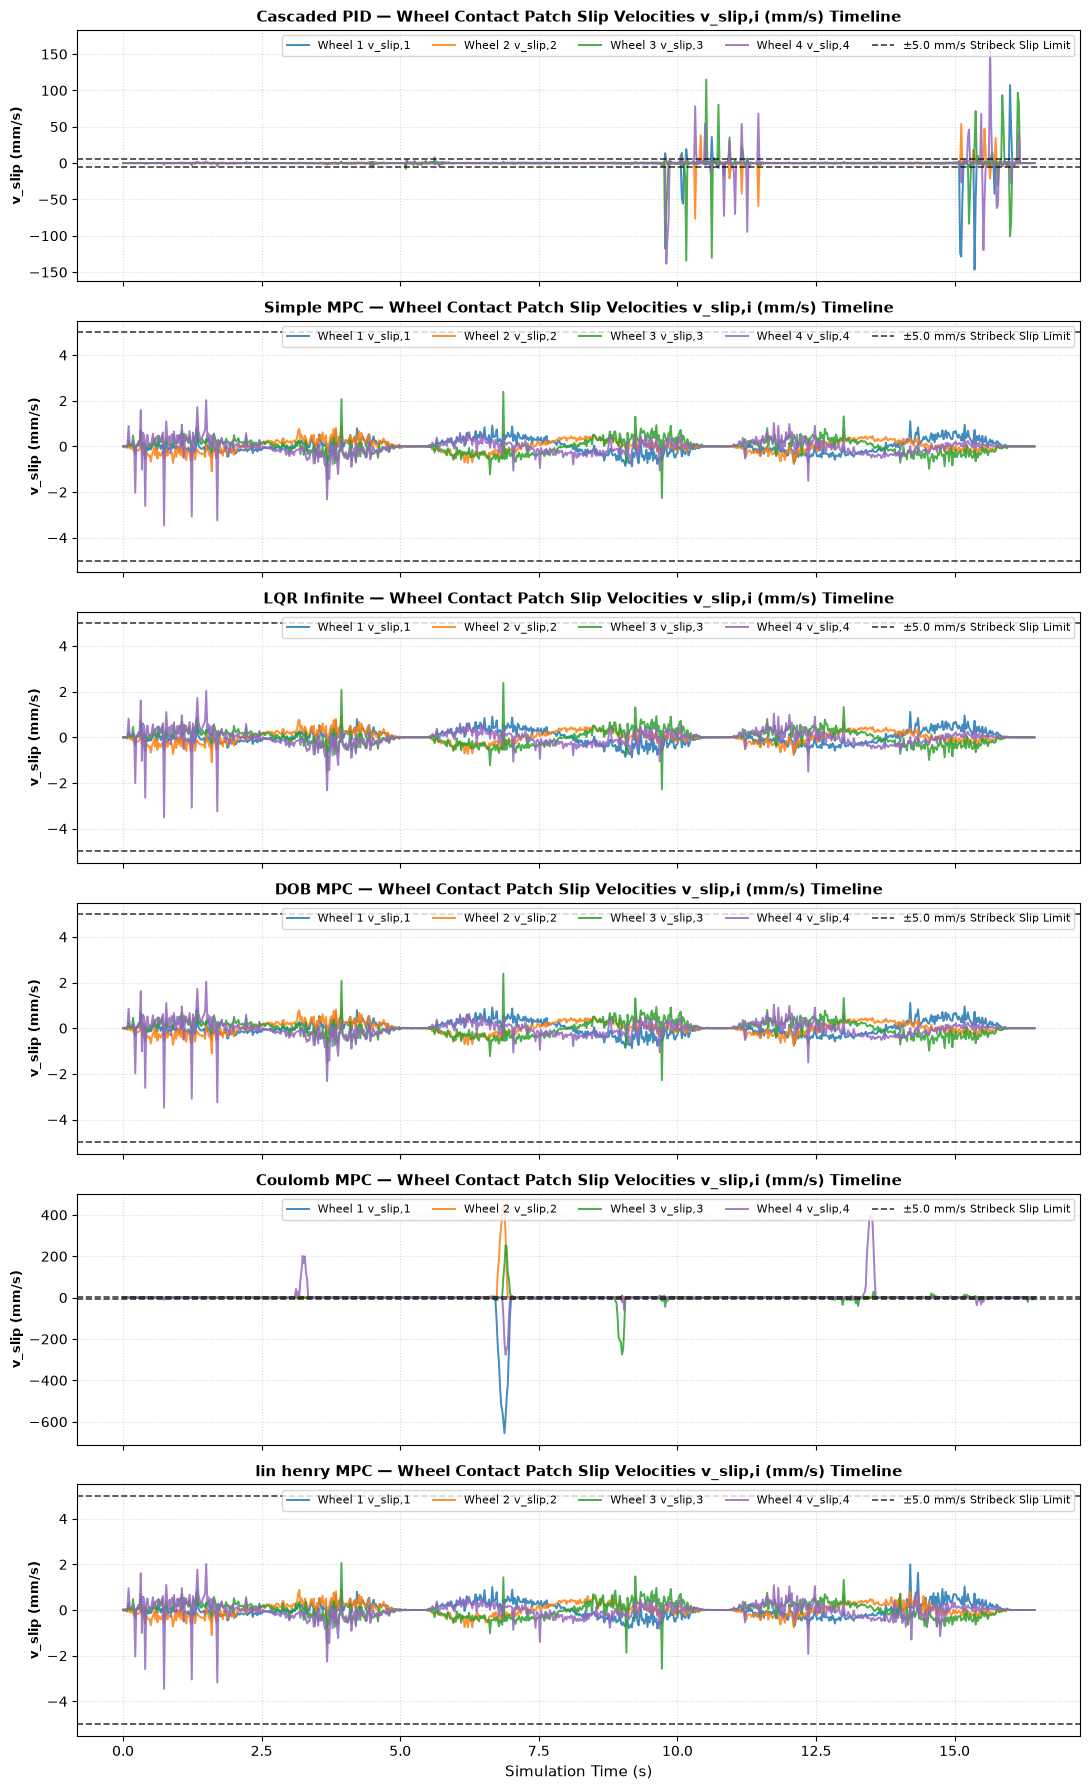

In [ ]:
print("\n" + "="*164)
print("              WAYPOINT PATH TRACKING SUMMARY")
print("="*164)
# print headers for table
headers = ["Controller", "RMS Time Err (cm)", "Max Spatial Err (cm)", "Max Slip (mm/s)", "Step Time (ms)", "Max Input (V) "]
for i in range(len(WAYPOINTS)-1):
    headers.append(f"WP{i+1} Settled (s)")    # was "Arrival"; within ARRIVE_THRESHOLD_POS and below ARRIVE_THRESHOLD_VEL
for header in headers:
    print(f"{header:<17} | ",end="")
print("")
print("-" * 164)

# print content per controller
for name in Controller_Dictionary.keys():
    res = results_multi_db[name]
    rms_time_err=np.sqrt(np.mean(res['pos_err']**2)) * 100.0
    
    # Orthogonal cross-track spatial path distance error
    dx = res['pos'][:, 0, None] - POS_REF[:, 0][None, :]
    dy = res['pos'][:, 1, None] - POS_REF[:, 1][None, :]
    spatial_path_dist_max =np.max( np.min(np.hypot(dx, dy), axis=1))*100
    slip_max = np.max(np.abs(res['v_slip'])) * 1000.0 # mm/s
    print(f"{name:<17} | {rms_time_err:<17.2f} | {spatial_path_dist_max:<17.2f} | {slip_max:<17.2f} | {(res['exec_time'] / N_STEPS) * 1000.0 :<17.2f} | {np.max(np.abs(res['V_cmd'])):<17.2f} |",end="")
    for arrival in res['arrival_times'][1:]:
        arrival_time = f"{arrival:.2f}s" if arrival else 'X not attained'   # was 'No Arrival'
        print(f"{arrival_time:<17} | ",end="")
    print("")

print("="*164)

# =======================================================================
# DIAGNOSTIC VISUALIZATION SUITE (6 PLOTS)
# =======================================================================

# PLOT 1: 2D Multi-Waypoint Executed Trajectories & Target Spheres
fig1, ax1 = plt.subplots(figsize=(11, 8))
ax1.plot(POS_REF[:, 0], POS_REF[:, 1], 'k--', lw=2.0, alpha=0.6, label='Desired Reference Path')

for idx, wp in enumerate(WAYPOINTS):
    ax1.plot(wp[0], wp[1], 'ro', ms=8, zorder=8)
    circle = Circle((wp[0], wp[1]), ARRIVE_THRESHOLD_POS, color='g', fill=True, alpha=0.25, zorder=3)
    ax1.add_patch(circle)
    ax1.text(wp[0]+0.08, wp[1]+0.08, f'WP{idx}\n({wp[0]:.1f}m, {wp[1]:.1f}m)', fontsize=9.5, fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.85))
    u_fwd = -np.sin(wp[2]) * 0.2
    v_fwd =  np.cos(wp[2]) * 0.2
    ax1.annotate('', xy=(wp[0] + u_fwd, wp[1] + v_fwd), xytext=(wp[0], wp[1]),
                        arrowprops=dict(arrowstyle="->", color='g', lw=1))
    
for name, ctuple in Controller_Dictionary.items():
    color = ctuple[2]
    res = results_multi_db[name]
    ax1.plot(res['pos'][:, 0], res['pos'][:, 1], color=color, lw=1.8, label=name, zorder=5)
    pos=res['pos']
    step_jump = max(1, len(res['pos']) // 10)
    indices = np.arange(0, len(res['pos']), step_jump)
    for idx in indices:
        xi, yi, thi = res['pos'][idx, 0], res['pos'][idx, 1], pos[idx, 2]
        u_fwd = -np.sin(thi) * 0.2
        v_fwd =  np.cos(thi) * 0.2
        ax1.annotate('', xy=(xi + u_fwd, yi + v_fwd), xytext=(xi, yi),
                    arrowprops=dict(arrowstyle="->", color=color, lw=1))
    # An X for each waypoint it did not attain, where it was when the path moved on from that waypoint
    # (the runner moves on 0.5 s before the next waypoint's timestamp; the last waypoint: the end of the run)
    for i_wp in range(1, len(WAYPOINTS)):
        if res['arrival_times'][i_wp] is None:
            t_moved_on = WP_TIMESTAMPS[i_wp] - 0.5 if i_wp < len(WAYPOINTS) - 1 else res['t'][-1]
            k_moved_on = min(int(round(t_moved_on / DT_CTRL)), len(pos) - 1)
            ax1.plot(pos[k_moved_on, 0], pos[k_moved_on, 1], 'X', color=color, mec='k', ms=10, zorder=9)
ax1.plot([], [], 'X', color='grey', mec='k', ms=10, ls='none', label='X: not attained (where it was when the path moved on)')

ax1.set_title(f'Waypoint Executed 2D Controller Trajectories', fontsize=12, fontweight='bold')
ax1.set_xlabel('Global X Position (m)', fontsize=11)
ax1.set_ylabel('Global Y Position (m)', fontsize=11)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper left', fontsize='small')
ax1.set_aspect('equal')
plt.tight_layout()
plt.show()


# PLOT 2: Robot Linear Speed Magnitude & Radial Angular Velocity Subplots Over Time
fig3, axs3 = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

v_lin_ref = np.hypot(VEL_REF[:, 0], VEL_REF[:, 1])
w_yaw_ref_deg = np.degrees(np.abs(VEL_REF[:, 2]))

# Subplot 3A: Linear Speed Magnitude ||v_lin||
axs3[0].plot(T_REF, v_lin_ref, 'k--', lw=2.0, alpha=0.7, label='Reference Speed', zorder=2)
for name, ctuple in Controller_Dictionary.items():
    color = ctuple[2]
    res_v = results_multi_db[name]['v_local']
    v_lin_act = np.hypot(res_v[:, 0], res_v[:, 1])
    axs3[0].plot(T_REF, v_lin_act, color=color, lw=1.8, label=name, zorder=4)
axs3[0].set_ylabel('Linear Speed (m/s)', fontsize=10, fontweight='bold')
axs3[0].set_title('Chassis Linear Speed Magnitude ||v_lin|| = sqrt(vx^2 + vy^2)', fontsize=11, fontweight='bold')
axs3[0].grid(True, linestyle=':', alpha=0.6)
axs3[0].legend(loc='upper right', fontsize='small', ncol=3)

# Subplot 3B: Radial / Angular Velocity Magnitude |w_yaw|
axs3[1].plot(T_REF, w_yaw_ref_deg, 'k--', lw=2.0, alpha=0.7, label='Reference Yaw Rate', zorder=2)
for name, ctuple in Controller_Dictionary.items():
    color = ctuple[2]
    w_yaw_act_deg = np.degrees(np.abs(results_multi_db[name]['v_local'][:, 2]))
    axs3[1].plot(T_REF, w_yaw_act_deg, color=color, lw=1.8, label=name, zorder=4)
axs3[1].set_ylabel('Angular Rate (°/s)', fontsize=10, fontweight='bold')
axs3[1].set_xlabel('Simulation Time (s)', fontsize=11)
axs3[1].set_title('Chassis Radial/Angular Velocity Magnitude |w_yaw| ', fontsize=11, fontweight='bold')
axs3[1].grid(True, linestyle=':', alpha=0.6)
axs3[1].legend(loc='upper right', fontsize='small', ncol=3)

plt.tight_layout()
plt.show()

# PLOT 4: Relative Tracking Errors Delta X, Delta Y, Delta Theta Subplots
fig4, axs4 = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
x_ref = POS_REF[:, 0]
y_ref = POS_REF[:, 1]
th_ref = np.degrees(POS_REF[:, 2])

# Subplot A: Delta X Error
for idx, wp in enumerate(WAYPOINTS): 
    if idx<len(WAYPOINTS)-1:
        axs4[0].axvline(idx*(SEGMENT_DURATION+HOLD_DURATION)+SEGMENT_DURATION, color='k', linestyle='--', alpha=0.2)
        axs4[0].axvline(idx*(SEGMENT_DURATION+HOLD_DURATION)+SEGMENT_DURATION+HOLD_DURATION, color='k', linestyle='--', alpha=0.2)
    else:
        axs4[0].axvline(0, color='k', linestyle='--', alpha=0.2,label='Waypoints')


for name, ctuple in Controller_Dictionary.items():
    color = ctuple[2]
    dx_cm = (results_multi_db[name]['pos'][:, 0] - x_ref) * 100.0
    axs4[0].plot(T_REF, dx_cm, color=color, lw=1.8, label=name)
axs4[0].axhline(ARRIVE_THRESHOLD_POS * 100.0, color='g', linestyle=':', alpha=0.7, label=f'±{ARRIVE_THRESHOLD_POS * 100.0:.1f} cm Target Deadband Bounds')
axs4[0].axhline(-ARRIVE_THRESHOLD_POS * 100.0, color='g', linestyle=':', alpha=0.7)
axs4[0].set_ylabel('Delta X Error (cm)', fontsize=10, fontweight='bold')
axs4[0].set_title('Relative Position Tracking Error: Delta X = X_actual - X_ref (cm)', fontsize=11, fontweight='bold')
axs4[0].grid(True, linestyle=':', alpha=0.6)
axs4[0].legend(loc='upper right', fontsize='small', ncol=3)

# Subplot B: Delta Y Error
for idx, wp in enumerate(WAYPOINTS): 
    if idx<len(WAYPOINTS)-1:
        axs4[1].axvline(idx*(SEGMENT_DURATION+HOLD_DURATION)+SEGMENT_DURATION, color='k', linestyle='--', alpha=0.2)
        axs4[1].axvline(idx*(SEGMENT_DURATION+HOLD_DURATION)+SEGMENT_DURATION+HOLD_DURATION, color='k', linestyle='--', alpha=0.2)
    else:
        axs4[1].axvline(0, color='k', linestyle='--', alpha=0.2,label='Waypoints')

for name, ctuple in Controller_Dictionary.items():
    color = ctuple[2]
    dy_cm = (results_multi_db[name]['pos'][:, 1] - y_ref) * 100.0
    axs4[1].plot(T_REF, dy_cm, color=color, lw=1.8, label=name)
axs4[1].axhline(ARRIVE_THRESHOLD_POS * 100.0, color='g', linestyle=':', alpha=0.7, label=f'±{ARRIVE_THRESHOLD_POS * 100.0:.1f} cm Target Deadband Bounds')
axs4[1].axhline(-ARRIVE_THRESHOLD_POS * 100.0, color='g', linestyle=':', alpha=0.7)
axs4[1].set_ylabel('Delta Y Error (cm)', fontsize=10, fontweight='bold')
axs4[1].set_title('Relative Position Tracking Error: Delta Y = Y_actual - Y_ref (cm)', fontsize=11, fontweight='bold')
axs4[1].grid(True, linestyle=':', alpha=0.6)
axs4[1].legend(loc='upper right', fontsize='small', ncol=3)

# Subplot C: Delta Theta Error
for idx, wp in enumerate(WAYPOINTS): 
    if idx<len(WAYPOINTS)-1:
        axs4[2].axvline(idx*(SEGMENT_DURATION+HOLD_DURATION)+SEGMENT_DURATION, color='k', linestyle='--', alpha=0.2)
        axs4[2].axvline(idx*(SEGMENT_DURATION+HOLD_DURATION)+SEGMENT_DURATION+HOLD_DURATION, color='k', linestyle='--', alpha=0.2)
    else:
        axs4[2].axvline(0, color='k', linestyle='--', alpha=0.2,label='Waypoints')

for name, ctuple in Controller_Dictionary.items():
    color = ctuple[2]
    dth_deg = np.degrees((results_multi_db[name]['pos'][:, 2] - POS_REF[:, 2] + np.pi) % (2.0 * np.pi) - np.pi)
    axs4[2].plot(T_REF, dth_deg, color=color, lw=1.8, label=name)
axs4[2].axhline(ARRIVE_THRESHOLD_THETA , color='g', linestyle=':', alpha=0.7, label=f'±{ARRIVE_THRESHOLD_THETA:.1f} cm Target Theta')
axs4[2].axhline(-ARRIVE_THRESHOLD_THETA , color='g', linestyle=':', alpha=0.7)
axs4[2].set_ylabel('Delta Theta Error (°)', fontsize=10, fontweight='bold')
axs4[2].set_xlabel('Simulation Time (s)', fontsize=11)
axs4[2].set_title('Relative Heading Angle Tracking Error: Delta Theta = Theta_actual - Theta_ref (°)', fontsize=11, fontweight='bold')
axs4[2].grid(True, linestyle=':', alpha=0.6)
axs4[2].legend(loc='upper right', fontsize='small', ncol=3)

plt.tight_layout()
plt.show()


# PLOT 6: Motor Terminal Voltages & Armature Currents Subplots (Twin Y-Axes per Controller Type)
fig6, axs6 = plt.subplots(len(Controller_Dictionary), 1, figsize=(11, 15), sharex=True)

v_lim = SIMULATION_PARAMATERS['V_max']
i_lim = SIMULATION_PARAMATERS['I_max']

for idx, (name, ctuple) in enumerate(Controller_Dictionary.items()):
    ax_v = axs6[idx]
    ax_i = ax_v.twinx()
    
    res = results_multi_db[name]
    V_data = res['V_cmd']
    I_data = res['I']
    
    # Motor Voltages (Primary Left Axis)
    colors_v = ['blue', 'cyan', 'navy', 'royalblue']
    for w in range(4):
        ax_v.plot(T_REF, V_data[:, w], color=colors_v[w], lw=1.2, alpha=0.85, label=f'V{w+1}')
    
    # Supply Voltage Limits (±V_max)
    ax_v.axhline(v_lim, color='red', linestyle='--', lw=1.2, alpha=0.75, label=f'±{v_lim:.1f}V Voltage Ceiling')
    ax_v.axhline(-v_lim, color='red', linestyle='--', lw=1.2, alpha=0.75)
    ax_v.set_ylim(-v_lim * 1.15, v_lim * 1.15)
    ax_v.set_ylabel('Voltage (V)', fontsize=9.5, fontweight='bold', color='darkblue')
    
    # Motor Currents (Secondary Right Axis)
    colors_i = ['darkred', 'crimson', 'darkorange', 'coral']
    for w in range(4):
        ax_i.plot(T_REF, I_data[:, w], color=colors_i[w], linestyle='--', lw=1.2, alpha=0.85, label=f'I{w+1}')
        
    # Over-Current Limits (±I_max)
    ax_i.axhline(i_lim, color='darkorange', linestyle=':', lw=1.5, alpha=0.85, label=f'±{i_lim:.1f}A Over-Current Limit')
    ax_i.axhline(-i_lim, color='darkorange', linestyle=':', lw=1.5, alpha=0.85)
    ax_i.set_ylim(-i_lim * 1.2, i_lim * 1.2)
    ax_i.set_ylabel('Current (A)', fontsize=9.5, fontweight='bold', color='darkred')
    
    # Labels & Title
    ax_v.set_title(f'{name} — Motor Terminal Voltages (V) & Armature Currents (A) Timeline', fontsize=11, fontweight='bold')
    ax_v.grid(True, linestyle=':', alpha=0.5)
    
    # Combine Legends
    lines_v, labels_v = ax_v.get_legend_handles_labels()
    lines_i, labels_i = ax_i.get_legend_handles_labels()
    ax_v.legend(lines_v + lines_i, labels_v + labels_i, loc='upper right', fontsize=8, ncol=5)

axs6[-1].set_xlabel('Simulation Time (s)', fontsize=11)
plt.tight_layout()
plt.show()

# PLOT 7 : Wheel Contact Patch Slip Velocity Subplots per Controller Type
fig7, axs7 = plt.subplots(len(Controller_Dictionary), 1, figsize=(11, 3 * len(Controller_Dictionary)), sharex=True)

wheel_colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:purple']
vs_mm_s = SIMULATION_PARAMATERS.get('slip_velocity_limit', 0.005) * 1000.0 # the Coulomb observer's slip scale (was lugre_damping_slip, removed with the damping; same 5 mm/s)

for idx, (name, ctuple) in enumerate(Controller_Dictionary.items()):
    ax_s = axs7[idx]
    res = results_multi_db[name]
    v_slip_mm_s = res['v_slip'] * 1000.0 # Convert m/s to mm/s
    
    for w in range(4):
        ax_s.plot(T_REF, v_slip_mm_s[:, w], color=wheel_colors[w], lw=1.4, alpha=0.85, label=f'Wheel {w+1} v_slip,{w+1}')
        
    ax_s.axhline(vs_mm_s, color='black', linestyle='--', lw=1.2, alpha=0.75, label=f'±{vs_mm_s:.1f} mm/s Stribeck Slip Limit')
    ax_s.axhline(-vs_mm_s, color='black', linestyle='--', lw=1.2, alpha=0.75)
    
    ax_s.set_ylabel('v_slip (mm/s)', fontsize=9.5, fontweight='bold')
    ax_s.set_title(f'{name} — Wheel Contact Patch Slip Velocities v_slip,i (mm/s) Timeline', fontsize=11, fontweight='bold')
    ax_s.grid(True, linestyle=':', alpha=0.5)
    ax_s.legend(loc='upper right', fontsize=8, ncol=5)

axs7[-1].set_xlabel('Simulation Time (s)', fontsize=11)
plt.tight_layout()
plt.show()



## UNIT CIRCLE PATH COMPARISON FOR SPEED TEST

In [ ]:
#################################################
# REDEFINING THE WAYPOINT TO UNIT CIRCLE ANALYSIS
#################################################

UNITCIRCLE_WP=0.25
UNITCIRCLE_STEP=0.25

THETA_BOUNDS=[-90,90]
THETA_STEP = 20
theta_arry_runner=np.arange(THETA_BOUNDS[0], THETA_BOUNDS[1], THETA_STEP)
ORIENTATION_BOUNDS=[-180,180]
orient_arry_runner=np.arange(ORIENTATION_BOUNDS[0], ORIENTATION_BOUNDS[1], THETA_STEP)

SEGMENT_DURATION = 3.0
HOLD_DURATION = 1.0

####### DEFINING RUNNER FOR ALL POSITIONS 
def run_unitcirlce_benchmark(name,ctuple, enable_deadband=ENABLE_DEADBAND):
    print(f"\nExecuting Unit Circle Benchmark for {name} for {SEGMENT_DURATION+HOLD_DURATION}s")
    distances_unit_circle_results = []
    UNITCIRCLE_WP=1

    for theta in theta_arry_runner:
        for orient in orient_arry_runner:
            THETA=theta
            ORIENTATION = orient
            max_dist=None
            
            while max_dist ==None:

                x_wp = UNITCIRCLE_WP*np.cos(np.radians(THETA))
                y_wp = UNITCIRCLE_WP*np.sin(np.radians(THETA))
                t_wp=np.radians(ORIENTATION)
                WAYPOINTS = [
                    np.array([0.0, 0.0, 0.0]),
                    np.array([x_wp, y_wp, t_wp])
                ]

                path_data=PathGenerator_Multi.generate_waypoints_sequence(waypoints=WAYPOINTS,segment_duration=SEGMENT_DURATION,segment_hold=HOLD_DURATION)

                WP_TIMESTAMPS = path_data['segment_boundaries']
                POS_REF = path_data['pos']
                VEL_REF = path_data['vel']
                N_STEPS = len(path_data['pos'])
                T_REF = path_data['t']
                V_LOCAL_REF = path_data['pos_local']

                #print(f"\nExecuting Unit Circle Benchmark for ......... for .....s")
                res=run_multi_waypoint_benchmark(ctuple, N_STEPS, WAYPOINTS, WP_TIMESTAMPS,
                                                 POS_REF, VEL_REF, enable_deadband=enable_deadband)   # her path arguments, as section 1
                
                if res['arrival_times'][1]==None:
                    max_dist=UNITCIRCLE_WP-UNITCIRCLE_STEP
                else:
                    UNITCIRCLE_WP=UNITCIRCLE_WP+UNITCIRCLE_STEP
            distances_unit_circle_results.append(max_dist)
            print(f"Theta: {THETA:<5.1f} | Orient: {ORIENTATION:<5.1f} |Max: {max_dist:<5.2f}")


run_unitcirlce_benchmark('pid',('pid', ctrl_PID, 'tab:red'))


Executing Unit Circle Benchmark for pid for 4.0s


KeyboardInterrupt: 